In [1]:
import os
import pandas as pd
import numpy as np
import random
import torch
from torch.utils.data import  DataLoader, Subset
from notebooks.util.data_preparing import  evaluate_results
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE 
import matplotlib.pyplot as plt
import os
import torch
import torch.nn.functional as F
from transformer_AEViT_1D import ViTAutoencoderConfig, build_model, pretrain_one_epoch, validate,SplitFolderNpyDataset,build_split_and_balance_dataset
from notebooks.util.data_preparing import  evaluate_results,evaluate_test_data, plot_confusion_matrix  
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner, ThresholdPruner
import time 
from pathlib import Path
import os
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import torch
from torch.utils.data import Dataset, Subset
from sklearn.model_selection import train_test_split
from torch.utils.data import ConcatDataset
import torch.nn as nn
import torch.nn.functional as F
from einops.layers.torch import Rearrange
from einops import rearrange, repeat
from dataclasses import dataclass
from typing import Optional
from typing import Dict, Optional
import math
from torch.utils.data import DataLoader, Subset
from collections import Counter


SPLIT_SEED = 42                     
SEEDS = [7,17, 27, 37, 47]          
def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":16:8"  
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

def make_worker(seed_base: int):
    def _seed_worker(worker_id):
        s = seed_base + worker_id
        np.random.seed(s); random.seed(s)
    return _seed_worker


def _fmt_hms(seconds: float) -> str:
    m, s = divmod(int(seconds), 60)
    h, m = divmod(m, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"

    
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found, using CPU")




# tgt_dir = '../data/New Data/CICIDS2018/data_pcaps_5'
tgt_dir = '../data/New Data/NB15/feature_out_5/_MERGED_ALL_NPY'

# =========================
# Adjustable input format
# =========================
INPUT_MODE = "packet_2d"   # "flat_1d" or "packet_2d"
# INPUT_MODE = "flat_1d"
PACKET_SHAPE = (5, 96)     # 5 packets, each 96 bytes
# train_ds = SplitFolderNpyDataset(
#     Path(tgt_dir) / "train",
#     use_label_file=False,
#     input_mode=INPUT_MODE,
#     packet_shape=PACKET_SHAPE,
# )

# test_ds = SplitFolderNpyDataset(
#     Path(tgt_dir) / "test",
#     use_label_file=False,
#     input_mode=INPUT_MODE,
#     packet_shape=PACKET_SHAPE,
# )


# train_subset, test_subset, benign_idx_train = build_split_and_balance_dataset(
#     full_ds=None,
#     train_ds=train_ds, 
#     test_ds=test_ds, 
#     benign_name="benign", 
#     split_ratio=0.7,
#     train_use_ratio=1.0,
#     test_use_ratio=1.0,
#     train_target_size= 700000,   
#     max_test_size_per_class= 10000,
#     seed=42
# )

full_ds = SplitFolderNpyDataset(
    Path(tgt_dir),
    use_label_file=False,
    input_mode=INPUT_MODE,
    packet_shape=PACKET_SHAPE,
)

train_subset, test_subset, benign_idx_train = build_split_and_balance_dataset(
    full_ds=full_ds,
    train_ds=None,
    test_ds=None,
    benign_name="benign", 
    split_ratio=0.7,
    train_use_ratio=1.0,
    test_use_ratio=1.0,
    train_target_size= 150000,   
    max_test_size_per_class= 10000,
    seed=42
)


/opt/conda/envs/py_3.12/lib/python3.12/site-packages/redis/connection.py:77: UserWarning: redis-py works best with hiredis. Please consider installing
  warnings.warn(msg)
/opt/conda/envs/py_3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using GPU: AMD Instinct MI300X
[Dataset] Loaded from /mlsteam/data/New Data/NB15/feature_out_5/_MERGED_ALL_NPY, total samples: 4076921


/mlsteam/lab/transformer_AEViT_1D.py:40: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:206.)
  t = torch.from_numpy(np.array(x, copy=False)).float()


[Info] 測試集過大，限制為 10000
[Warn] 20% 區域中 benign/attack 數量不平衡，調整平衡基準 K=10000
--- 數據拆分報告 ---
原始總樣本數: 4076921
80% 區域總數: 2853844
80% 區域中的良性樣本數: 2829668
指定訓練集大小: 150000
最終訓練集大小: 150000
20% 區域總數: 1223077
平衡測試候選 benign 數: 10000
平衡測試候選 attack 數: 10000
實際使用測試比例: 1.00
最終測試集大小: 20000
benign_idx_val: 10


In [2]:

result_csv = 'results_AEViT_image_2018_96_5_1000000_1/SVDD_image/optuna/result_imgSVDD.csv'
model_dir = 'results_AEViT_image_2018_96_5_1000000_1/SVDD_image/optuna/models/'
# input_file = 'data/NF-CICIDS2018-v3.parquet'


df = pd.read_csv(result_csv)
top_trials = df.head(1)

print(f"原始筆數：{len(df)}，保留筆數：{len(top_trials)}")

原始筆數：9，保留筆數：1


[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias
   encoder.5.mlp.fc2.weight
   encoder.5.mlp.fc2.bias
   bottleneck.0.weight
   bottleneck.0.bias
   bottleneck.2.weight
   bottleneck.2.bias
   decoder.0.norm1.weight
   decoder.0.norm1.bias
   decoder.0.attn.in_proj_weight
   decoder.0.attn.in_proj_bias
   decoder.0.attn.out_proj.weight
   decoder.0.attn.out_proj.bias
   decoder.0.norm2.weight
   decoder.0.norm2.bias
   decoder.0.mlp.fc1.weight
   decoder.0.mlp.fc1.bias
   decoder.0.mlp.fc2.weight
   decoder.0.mlp.fc2.bias
   decoder.1.norm1.weight
   decoder.1.norm1.bias
   decoder.1.attn.in_proj_weight
   decoder.1.attn.in_proj_bias
  

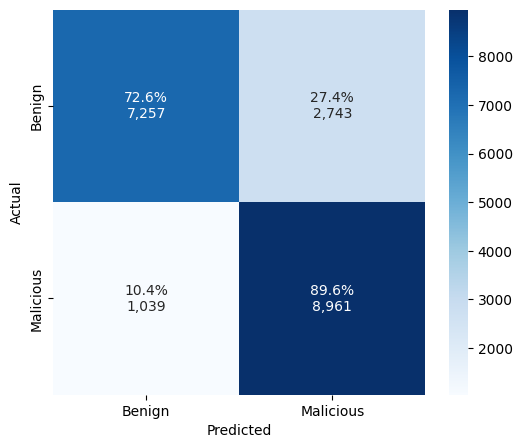

SEED:7
Evaluation Metrics for  trial 1
Threshold:            0.0001
Recall:               0.8961
Precision:            0.7656
F1-score:             0.8257
AUC (PR Curve):       0.8531
AUROC (ROC Curve):    0.8955
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias
   encoder.5.mlp.fc2.weight
   encoder.5.mlp.fc2.bias
   bottleneck.0.weight
   bottleneck.0.bias
   bottleneck.2.weight
   bottleneck.2.bias
   decoder.0.norm1.weight
   decoder.0.norm1.bias
   decoder.0.attn.in_proj_weight
   decoder.0.attn.in_proj_bias
   decoder.0.attn.out_proj.weight
   decoder.0.attn.out_proj.bias
   decoder.0.norm2.weight
   decoder.0.norm2.bias
   decoder.

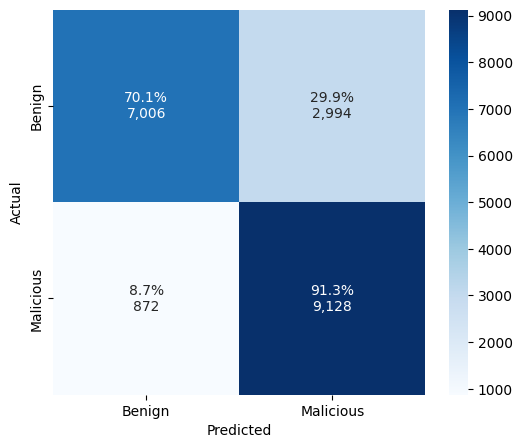

SEED:17
Evaluation Metrics for  trial 1
Threshold:            0.0001
Recall:               0.9128
Precision:            0.7530
F1-score:             0.8252
AUC (PR Curve):       0.8569
AUROC (ROC Curve):    0.8983
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias
   encoder.5.mlp.fc2.weight
   encoder.5.mlp.fc2.bias
   bottleneck.0.weight
   bottleneck.0.bias
   bottleneck.2.weight
   bottleneck.2.bias
   decoder.0.norm1.weight
   decoder.0.norm1.bias
   decoder.0.attn.in_proj_weight
   decoder.0.attn.in_proj_bias
   decoder.0.attn.out_proj.weight
   decoder.0.attn.out_proj.bias
   decoder.0.norm2.weight
   decoder.0.norm2.bias
   decoder

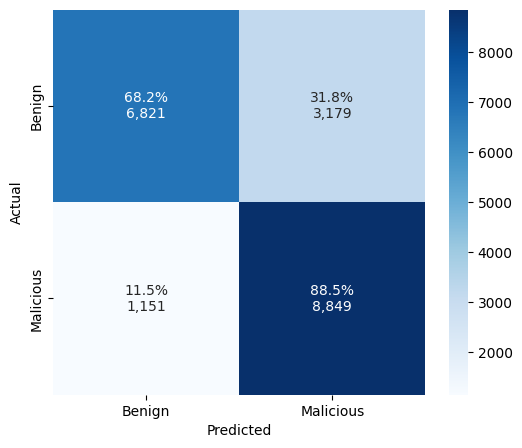

SEED:27
Evaluation Metrics for  trial 1
Threshold:            0.0000
Recall:               0.8849
Precision:            0.7357
F1-score:             0.8034
AUC (PR Curve):       0.8241
AUROC (ROC Curve):    0.8666
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias
   encoder.5.mlp.fc2.weight
   encoder.5.mlp.fc2.bias
   bottleneck.0.weight
   bottleneck.0.bias
   bottleneck.2.weight
   bottleneck.2.bias
   decoder.0.norm1.weight
   decoder.0.norm1.bias
   decoder.0.attn.in_proj_weight
   decoder.0.attn.in_proj_bias
   decoder.0.attn.out_proj.weight
   decoder.0.attn.out_proj.bias
   decoder.0.norm2.weight
   decoder.0.norm2.bias
   decoder

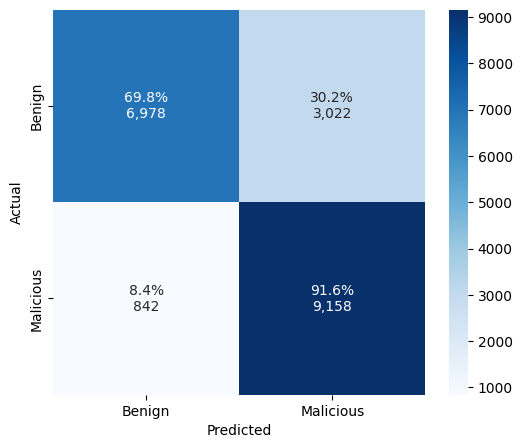

SEED:37
Evaluation Metrics for  trial 1
Threshold:            0.0001
Recall:               0.9158
Precision:            0.7519
F1-score:             0.8258
AUC (PR Curve):       0.8435
AUROC (ROC Curve):    0.8882
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias
   encoder.5.mlp.fc2.weight
   encoder.5.mlp.fc2.bias
   bottleneck.0.weight
   bottleneck.0.bias
   bottleneck.2.weight
   bottleneck.2.bias
   decoder.0.norm1.weight
   decoder.0.norm1.bias
   decoder.0.attn.in_proj_weight
   decoder.0.attn.in_proj_bias
   decoder.0.attn.out_proj.weight
   decoder.0.attn.out_proj.bias
   decoder.0.norm2.weight
   decoder.0.norm2.bias
   decoder

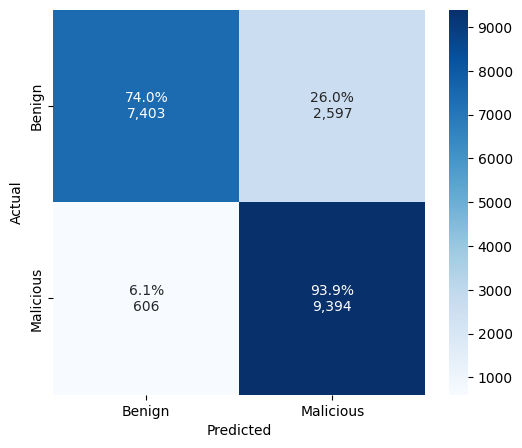

SEED:47
Evaluation Metrics for  trial 1
Threshold:            0.0001
Recall:               0.9394
Precision:            0.7834
F1-score:             0.8543
AUC (PR Curve):       0.8631
AUROC (ROC Curve):    0.9084


In [3]:
rows = []
final_csv = "results_AEViT_image_2018_96_5_1000000_1/SVDD_image/optuna/models/ft_5layer_150000/fine_tune_results.csv"
os.makedirs(os.path.dirname(final_csv), exist_ok=True)

# pretrain_save_dir = 'results_SVDD_image_2018_v2_1/SVDD_image/optuna/models/pretrain_backup_1'
# os.makedirs(pretrain_save_dir, exist_ok=True)

ft_save_dir = 'results_AEViT_image_2018_96_5_1000000_1/SVDD_image/optuna/models/ft_5layer_150000'
os.makedirs(ft_save_dir, exist_ok=True)

all_idx = np.arange(len(train_subset))
train_idx, val_idx = train_test_split(
    all_idx, test_size=0.2, random_state=42, shuffle=True
)

seed_time = {}

for run_seed in SEEDS:
    set_global_seed(run_seed)
    worker_init_fn = make_worker(run_seed)
    g = torch.Generator()
    g.manual_seed(run_seed)

    seed_ft_accum = 0.0

    for _, trial_row in top_trials.iterrows():

        trial_number = int(trial_row["number"])
        bs = int(trial_row["params_batch_size"])
        # lr = float(trial_row["params_lr"])
        epochs = 50
        t0 = time.perf_counter()


        # cfg = ViTAutoencoderConfig(
        #     input_mode="packet_2d",
        #     packet_shape=(5, 96),
        #     patch_size=12,      # 96 / 12 = 8 patches
        #     embed_dim=192,
        #     latent_dim=64,
        #     depth=4,
        #     decoder_depth=2,
        #     num_heads=6,
        #     mlp_ratio=3.0,
        #     dropout=0.1,
        #     drop_path_rate=0.1,
        # )

        embed_dim = int(trial_row["params_embed_dim"])
        head_dim = int(trial_row["params_head_dim"])
        latent_dim = int(trial_row["params_latent_dim"])
        depth = int(trial_row["params_depth"])
        decoder_depth = int(trial_row["params_decoder_depth"])
        num_heads = embed_dim // head_dim
    
        cfg = ViTAutoencoderConfig(
            input_mode="packet_2d",
            packet_shape=(5, 96),
            patch_size=12,
            embed_dim=embed_dim,
            latent_dim=latent_dim,
            depth=depth,
            decoder_depth=decoder_depth,
            num_heads=num_heads,
            mlp_ratio=3.0,
            dropout=0.1,
            drop_path_rate=0.1,
        )
        

        # Create DataLoaders
        train_loader = DataLoader(
            Subset(train_subset, train_idx),
            batch_size=bs,
            shuffle=True,
            num_workers=2,
            pin_memory=True,
            worker_init_fn=worker_init_fn,
            generator=g
        )

        val_loader = DataLoader(
            Subset(train_subset, val_idx),
            batch_size=bs,
            shuffle=False,
            num_workers=2,
            pin_memory=True,
            worker_init_fn=worker_init_fn,
            generator=g
        )

        test_loader = DataLoader(
            test_subset,
            batch_size=bs,
            shuffle=False,
            num_workers=2,
            pin_memory=True,
            worker_init_fn=worker_init_fn,
            generator=g
        )

        model = build_model(cfg)
        model = model.to(cfg.device)

        model_path = os.path.join(model_dir, f"AE_trial_{trial_number}.pt")
        ckpt = torch.load(model_path, map_location=cfg.device)
        model.load_state_dict(ckpt["state_dict"])

        # =========================================
        # 1. Freeze all parameters first
        # =========================================
        for p in model.parameters():
            p.requires_grad = False
        
        
        # =========================================
        # 2. Set the number of decoder blocks to unfreeze (⭐ key control)
        # =========================================
        num_decoder_blocks = 2 # ← Change this value (1, 2, 3, ...)
        num_encoder_blocks = 1
        
        # =========================================
        # 3. Unfreeze patch_head and decoder_norm
        # =========================================
        base_modules = ["patch_head", "decoder_norm","bottleneck"]
        
        for module_name in base_modules:
            if hasattr(model, module_name):
                module = getattr(model, module_name)
                for p in module.parameters():
                    p.requires_grad = True
            else:
                print(f"[Warning] model has no module named: {module_name}")
        
        
        # =========================================
        # 4. ⭐ Unfreeze only the last N decoder blocks
        # =========================================
        if hasattr(model, "decoder"):
            total_blocks = len(model.decoder)
        
            if num_decoder_blocks > total_blocks:
                raise ValueError(f"num_decoder_blocks={num_decoder_blocks} > total_blocks={total_blocks}")
        
            for i in range(total_blocks - num_decoder_blocks, total_blocks):
                print(f"[Info] Unfreezing decoder block {i}")
                for p in model.decoder[i].parameters():
                    p.requires_grad = True
        else:
            print("[Warning] model has no module named: decoder")

        if hasattr(model, "encoder"):
            total_blocks = len(model.encoder)
        
            if num_encoder_blocks > total_blocks:
                raise ValueError(f"num_encoder_blocks={num_encoder_blocks} > total_blocks={total_blocks}")
        
            for i in range(total_blocks - num_encoder_blocks, total_blocks):
                print(f"[Info] Unfreezing encoder block {i}")
                for p in model.encoder[i].parameters():
                    p.requires_grad = True
        else:
            print("[Warning] model has no module named: encoder")

        
        
        
        
        # =========================================
        # 5. Confirm which parameters will be trained
        # =========================================
        trainable_params = [n for n, p in model.named_parameters() if p.requires_grad]
        
        print("Trainable params:")
        for n in trainable_params:
            print("  ", n)
        
        
        # =========================================
        # 6. Safety check
        # =========================================
        trainable_parameters = [p for p in model.parameters() if p.requires_grad]
        
        if len(trainable_parameters) == 0:
            raise ValueError("No trainable parameters found after unfreezing.")
        opt = torch.optim.AdamW(trainable_parameters, lr=2e-4, weight_decay=0.0)

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=epochs * len(train_loader)
        )
        # Training
        best = float("inf")
        best_state = None
        patience = 10
        bad = 0

        for epoch in range(epochs):
            meters = pretrain_one_epoch(model, train_loader, opt, cfg, scheduler=scheduler)
            val = validate(model, val_loader, cfg)

            print(f"[{epoch:03d}] MSE_Loss={meters['loss']:.6f}  Val_MSE={val['val_loss']:.6f}")

            if val["val_loss"] < best - 1e-6:
                best = val["val_loss"]
                bad = 0
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
            else:
                bad += 1
                if bad >= patience:
                    print(f"Early stopping at epoch {epoch}")
                    break


        seed_ft_accum += (time.perf_counter() - t0)

        if best_state is not None:
            model.load_state_dict(best_state)

        ft_ckpt = {
            "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            "cfg": model.cfg.__dict__,
        }
        torch.save(ft_ckpt, os.path.join(ft_save_dir, f"SVDD_ft_trial_{trial_number}_{run_seed}.pt"))

        model.eval()
        scores = []
        y_true = []

        with torch.no_grad():
            for x, y in test_loader:
                x = x.to(cfg.device, non_blocking=True)
        
                recon, _ = model(x)
        
                # anomaly score = reconstruction MSE per-sample
                s = (recon - x).pow(2).flatten(1).mean(1)
        
                scores.append(s.detach().cpu().numpy())
                y_true.append(y.numpy())
        
        test_score = np.concatenate(scores, axis=0)
        y_true = np.concatenate(y_true, axis=0)
    
        print("[DEBUG] y_eval distribution:", Counter(y_true.tolist()))
        
        # Evaluation results
        test_metrics = evaluate_results(y_true, test_score)
        print(f"[DEBUG] AUROC: {test_metrics['auroc']:.4f}, F1: {test_metrics['f1']:.4f}")

        threshold = test_metrics['threshold']
        results = evaluate_test_data(y_true, test_score, threshold)


        recall = results['recall']
        precision = results['precision'] 
        f1 = results['f1'] 
        au_precision_recall = results['au_precision_recall'] 
        auroc = results["auroc"]
        
        
        plot_confusion_matrix(y_true, test_score,threshold, pos_label=-1)
    
        metrics_dict = {
        "seed": run_seed,
        "trial_number":trial_number,
        "recall": recall,
        "precision": precision,
        "f1": f1,
        "au_precision_recall": au_precision_recall,
        "auroc": auroc,
        "threshold": threshold
        }
        
        rows.append(metrics_dict)
        
        print(f"SEED:{run_seed}")
        print(f"Evaluation Metrics for  trial {trial_number}")
        print(f"Threshold:            {threshold:.4f}")
        print(f"Recall:               {recall:.4f}")
        print(f"Precision:            {precision:.4f}")
        print(f"F1-score:             {f1:.4f}")
        print(f"AUC (PR Curve):       {au_precision_recall:.4f}")
        print(f"AUROC (ROC Curve):    {auroc:.4f}")

    seed_time[run_seed] = seed_ft_accum

df = pd.DataFrame(rows)
df["seed_ft_total_sec"] = df["seed"].map(seed_time)
df["seed_ft_total_hms"] = df["seed_ft_total_sec"].apply(_fmt_hms)
df.to_csv(final_csv, index=False)


In [4]:
import numpy as np, pandas as pd
df_out = pd.DataFrame(rows)
summary = (
    df_out.groupby("trial_number")[["precision","recall","f1","auroc","au_precision_recall"]]
          .agg(["mean","std"])
          .round(4)
)
print("\n=== Seed-wise summary (per trial): mean ± std ===")
print(summary)
# It can also be saved separately:
summary.to_csv(final_csv.replace(".csv","_summary.csv"))


=== Seed-wise summary (per trial): mean ± std ===
             precision          recall              f1           auroc  \
                  mean     std    mean     std    mean     std    mean   
trial_number                                                             
1               0.7579  0.0178  0.9098  0.0208  0.8269  0.0181  0.8914   

                     au_precision_recall          
                 std                mean     std  
trial_number                                      
1             0.0156              0.8481  0.0152  
